In [1]:
# imports and configrations

In [55]:
from langsmith import Client
from pathlib import Path
from dotenv import load_dotenv
import langsmith as ls
import os

In [56]:
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, BaseMessage, AIMessage, ToolMessage
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END, add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from typing import TypedDict, Literal, Annotated
from typing_extensions import NotRequired

from pydantic import BaseModel, Field
from rich import print

In [57]:
env_path = Path.cwd().parent.parent / ".env"
load_dotenv(env_path)
openai_api_key = os.getenv("OPENAI_API_KEY")
langsmith_api_key = os.getenv("LANGSMITH_API_KEY")


In [58]:
os.environ["LANGSMITH_PROJECT"] = "simple-agent"
os.environ["LANGCHAIN_PROJECT"] = "simple-agent"
os.environ["LANGCHAIN_TRACING_V2"] = "true" 

In [59]:
# business logic

In [61]:
model = ChatOpenAI(
    model="gpt-4.1-mini",
    api_key=openai_api_key,
    temperature=0
)

In [62]:
# defining tools 

In [63]:
@tool
def add(num1:float, num2:float) -> float:
    """This tool is used to add two numbers"""
    return num1 + num2


@tool
def subtract(num1:float, num2:float) -> float:
    """This tool is used to subtract two numbers"""
    return num1 - num2

@tool
def multiply(num1:float, num2:float) -> float:
    """This tool is used to multiply two numbers"""
    return num1 * num2

@tool
def divide(num1:float, num2:float) -> float:
    """This tool is used to divide two numbers"""
    try:
        return num1 / num2
    except ZeroDivisionError:
        print("Error: Cannot divide by zero")
        return None

In [64]:
class State(BaseModel):
    messages: Annotated[list[BaseMessage], add_messages] = Field(default_factory=list)

In [65]:
# binding the model with the tools 
tools = [add, subtract, multiply, divide]
model_with_tools = model.bind_tools(tools)

In [66]:
def agent_node(state:State):
    # Since state is a Pydantic model, access attributes via dot notation
    messages = state.messages
    # Call the model using .invoke()
    response = model_with_tools.invoke(messages)
    # Return response in messages list to trigger add_messages reducer
    return {"messages": [response]}

If the message contains something like " What will be 2 added to 3", then the "model_with_tools" will return us something like this, and the "response" will similar to the same mentioned below.

AIMessage(
    content='',
    additional_kwargs={'refusal': None},
    response_metadata={
        'token_usage': {
            'completion_tokens': 19,
            'prompt_tokens': 150,
            'total_tokens': 169,
            'completion_tokens_details': {
                'accepted_prediction_tokens': 0,
                'audio_tokens': 0,
                'reasoning_tokens': 0,
                'rejected_prediction_tokens': 0,
                'text_tokens': None
            },
            'prompt_tokens_details': {
                'audio_tokens': 0,
                'cache_write_tokens': None,
                'cached_tokens': 0,
                'image_tokens': None,
                'text_tokens': None
            }
        },
        'model_provider': 'openai',
        'model_name': 'gpt-4.1-mini-2025-04-14',
        'system_fingerprint': 'fp_d6c29e5320',
        'id': 'chatcmpl-Egm6QlaTcM673dfIVURvrzjHqZHOm',
        'service_tier': 'default',
        'finish_reason': 'tool_calls',
        'logprobs': None
    },
    id='lc_run--01a1aa96-faa3-7667-a916-5f369e935202-0',
    tool_calls=[
        {
            'name': 'add',
            'args': {'num1': 2, 'num2': 3},
            'id': 'call_hANrlKFIto9XhZ9S8cuuhuwM',
            'type': 'tool_call'
        }
    ],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 150,
        'output_tokens': 19,
        'total_tokens': 169,
        'input_token_details': {'audio': 0, 'cache_read': 0},
        'output_token_details': {'audio': 0, 'reasoning': 0}
    }
)

Here, the tool is supposed to call so our AIMessage containing following 

content="",
tool_calls=[
    {
        'name':'add',
        'args': {'num1': 2, 'num2': 3},
        'id':'call_hANrlKFIto9XhZ9S8cuuhuwM'
    }
] 

By observing the same we can say that, if the response contains the tool_calls then we need to call a tool otherwise if the content is containing the descriptive message then we should just print the content.

For implementing the same we need a conditional node in langgraph

In [67]:
def should_continue(state: State):
    messages = state.messages
    last_message = messages[-1]

    if getattr(last_message, "tool_calls", None):
        return "tools"

    return "end" 

In [68]:
from langgraph.prebuilt import ToolNode

tools_node = ToolNode(tools)

In [48]:
# Build the graph

In [69]:
# defining the graph
graph = StateGraph(State)

# defining the nodes
graph.add_node("agent", agent_node)
graph.add_node("tools", tools_node)

# defining the edges
graph.add_edge(START, "agent")

graph.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)

# After executing tools, return to the agent
graph.add_edge("tools", "agent")

workflow = graph.compile()

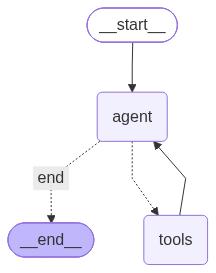

In [70]:
workflow

In [71]:
# making the instance of the state class
state = State()

# defining the configuration for the workflow
config = {
    "configurable": {
        "thread_id": "user_123"
    }
}

In [72]:
while True:

    user_query = input("Enter your query: ")

    # Check if the user wants to exit the program
    if user_query.lower() == "exit":
        print("Exiting the program.")
        break

    # Printing the user query
    print(f"User Query: {user_query}")

    human_message = HumanMessage(content=user_query)
    state.messages.append(human_message)

    response = workflow.invoke(state, config=config)

    # Sync state with returned messages so conversation history is preserved
    state.messages = response["messages"]

    print(f"AI Response: {state.messages[-1].content}\n")

User Query: hello

AI Response: Hello! How can I assist you today?

User Query: how are you

AI Response: I'm just a computer program, so I don't have feelings, but I'm here and ready to help you! How can I 
assist you today?

User Query: Can you please tell me what is 17 +96

AI Response: The sum of 17 and 96 is 113. Is there anything else you would like to know?

... (3 outputs left out)

AI Response: You're welcome! If you have any more questions or need assistance in the future, don't hesitate to 
reach out. Have a great day!

User Query: exit.

AI Response: Goodbye! Have a wonderful day! If you need help again, just come back.

Exiting the program.